# One night through the pipeline, service by service

This notebook follows **one real night** (`ucddb013`, moderate apnea) through all the services of the project,
**without Kafka, PostgreSQL or Docker**. It imports the code of each service directly
(the "logic" part of `detector.py`, `ahi_triage.py`, `train.py`, `gate.py` and `features.py`)
and passes the messages by hand, in the same order Kafka would.

```
data/clean/signals ─► device-simulator ─► raw-signals ─► apnea-detector ─┬─► alerts ───────► alert-service
   (.npz files)       (not written yet,    (1 msg/min)   (features +      │
                       simulated here)                    model + carbon)  └─► apnea-events ─► ahi-triage ─► results / night-results
                                                              ▲
                                       model-trainer ─────────┘ (models/model.joblib)
```

| Part | Service | What we look at |
|---|---|---|
| 1 | data | the raw signals of one night and the true labels |
| 2 | device-simulator | what a `raw-signals` message looks like |
| 2b | before `features.py` | the 4 numpy arrays of one minute, raw values, sensor gaps |
| 3 | `common/features.py` | how one minute becomes 42 numbers |
| 4 | model-trainer | training, F1, F1 gate (`gate.py`) |
| 5 | apnea-detector | SpO₂ < 80 % alerts, carbon rule, `apnea-events` messages |
| 6 | ahi-triage | AHI, severity, `night-results` message |
| 7 | all together | the 5 demo nights |

**To run it:** open this file from inside the repository (any folder of the repo), with
Python 3.12 to 3.14 and `pip install -r services/apnea-detector/requirements.txt pandas matplotlib jupyter`.
You can change `NIGHT` in the next cell to look at another night.

In [1]:
import os, sys, json, csv, time, importlib
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# find the repository root (the folder that contains services/)
ROOT = Path.cwd()
while not (ROOT / "services").exists():
    if ROOT.parent == ROOT:
        raise SystemExit("Start the notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)

# no database in this notebook
os.environ["USE_DB"] = "0"
for d in ["services/common", "services/apnea-detector", "services/ahi-triage", "services/model-trainer"]:
    sys.path.insert(0, str(ROOT / d))

import features as F      # services/common/features.py
import detector as D      # services/apnea-detector/detector.py   (part 1: logic)
import ahi_triage as T    # services/ahi-triage/ahi_triage.py     (part 1: logic)
import train as TR        # services/model-trainer/train.py
import gate as G          # services/model-trainer/gate.py

DATA = ROOT / "data" / "clean"
NIGHT = "ucddb013"        # demo nights: ucddb018 (mild) ucddb017 ucddb013 ucddb010 ucddb025 (very severe)

plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 40, "display.width", 200)
print("repository root:", ROOT)

repository root: /home/claude/barbaraklimektomatova/acc1ilv-cloud-and-ai-infrastructure-for-sleep-apnea-detection-


## 1. The data of one night

`data/clean/signals/<night>.npz` contains **only what the device measures**:

| signal | rate | values per minute |
|---|---|---|
| `spo2` | 1 Hz | 60 |
| `flow` (nose/mouth airflow) | 4 Hz | 240 |
| `thorax` (chest) | 4 Hz | 240 |
| `abdomen` (belly) | 4 Hz | 240 |

The **answers** (what the doctors scored) are kept apart, in `labels.csv`: one row per minute
with `event` = `normal` / `apnea` / `hypopnea`. They never go into Kafka; here we only use them to compare.

In [2]:
sig = np.load(DATA / "signals" / f"{NIGHT}.npz")
labels = pd.read_csv(DATA / "labels.csv")
lab = labels[labels.night_id == NIGHT].set_index("minute")
splits = {n["night_id"]: n for n in json.load(open(DATA / "splits.json"))}

minutes = len(sig["spo2"]) // 60
print(f"night {NIGHT}: {minutes} minutes ({minutes/60:.1f} h)")
print({k: sig[k].shape for k in sig.files})
print("true AHI (splits.json):", splits[NIGHT]["ahi"])
lab["event"].value_counts()

night ucddb013: 405 minutes (6.8 h)
{'spo2': (24300,), 'flow': (97200,), 'thorax': (97200,), 'abdomen': (97200,)}
true AHI (splits.json): 15.7


event
normal      334
hypopnea     71
Name: count, dtype: int64

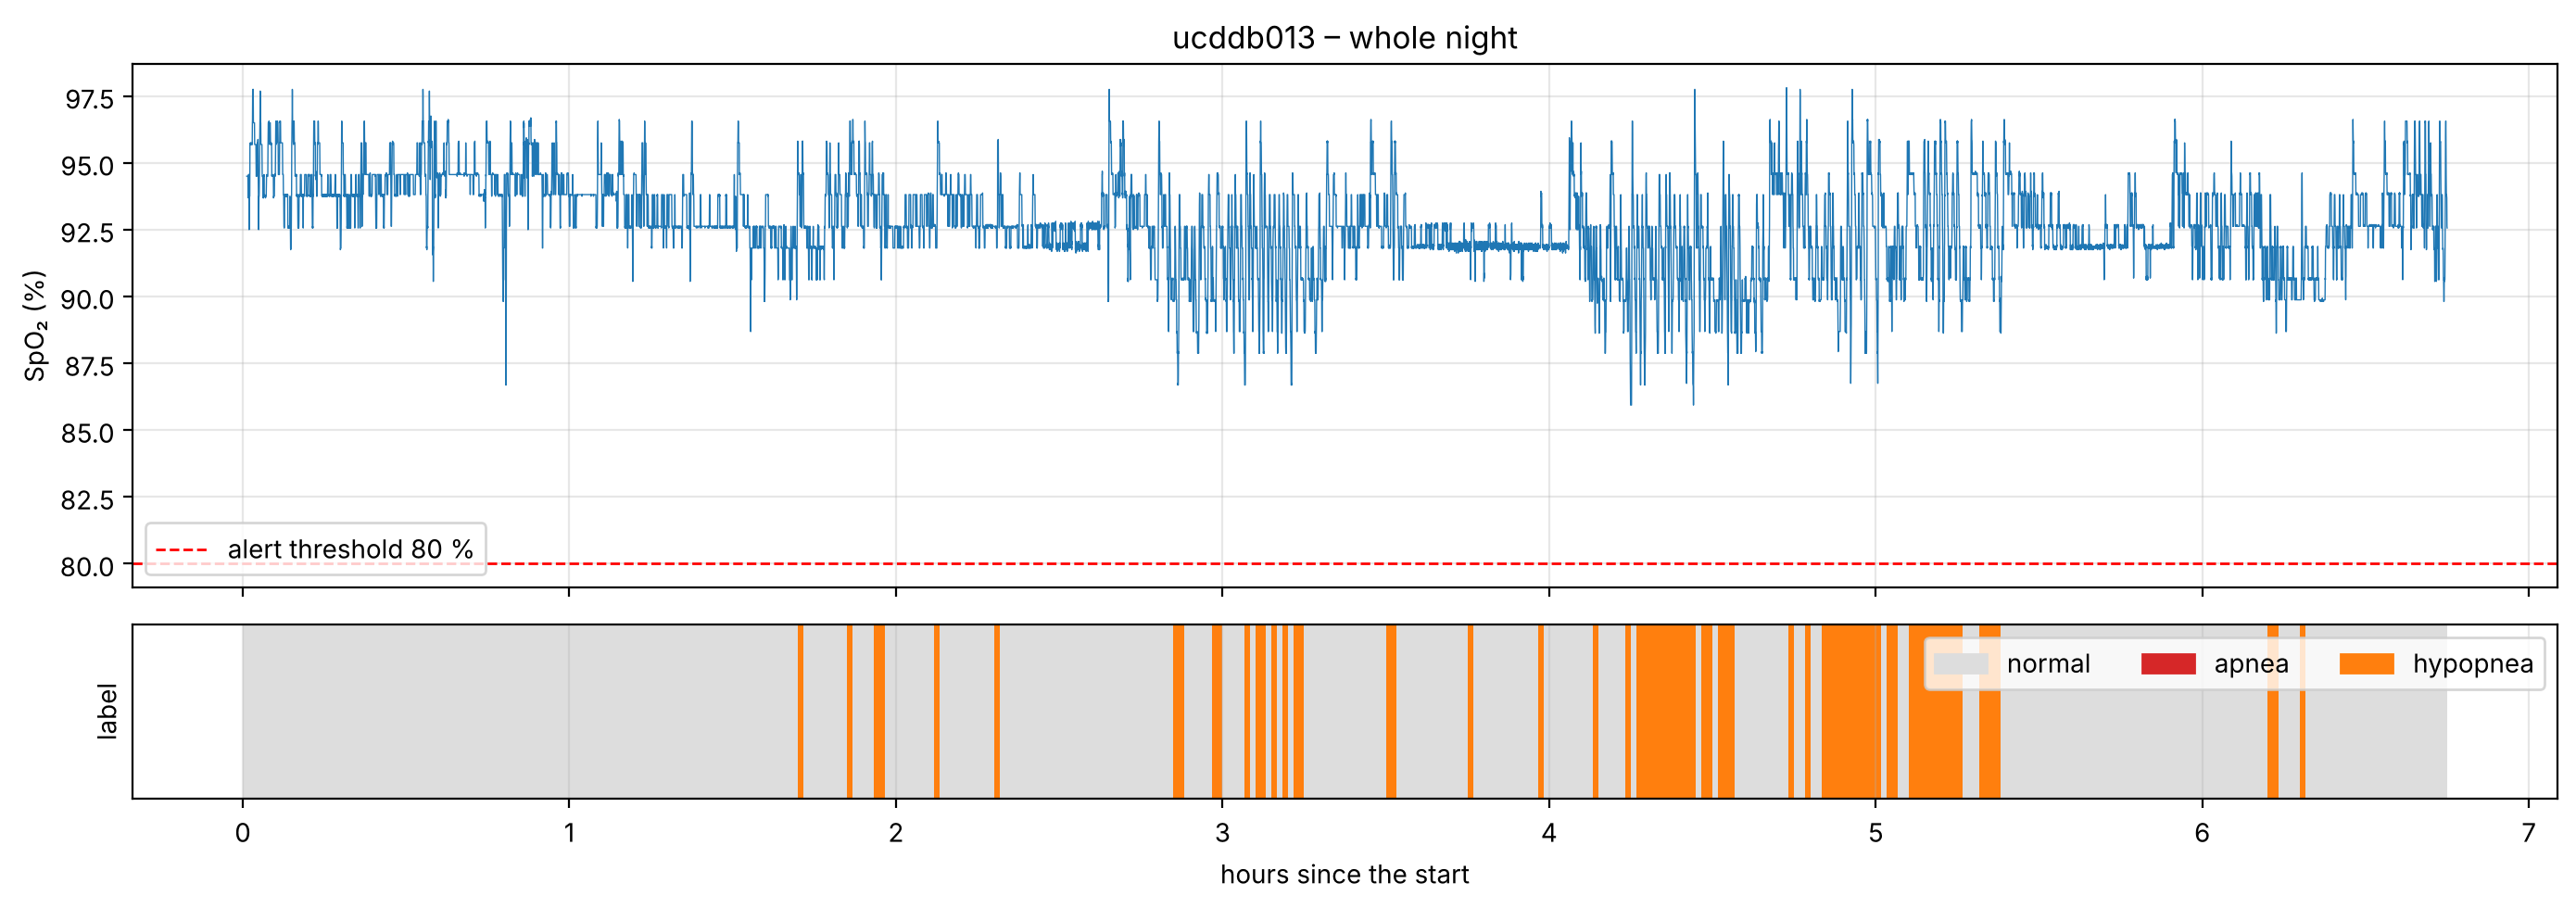

In [3]:
# the whole night: SpO2 + scored minutes
t_h = np.arange(len(sig["spo2"])) / 3600
fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(t_h, sig["spo2"], lw=0.5)
ax[0].axhline(80, color="red", ls="--", lw=1, label="alert threshold 80 %")
ax[0].set_ylabel("SpO₂ (%)"); ax[0].legend(loc="lower left"); ax[0].set_title(f"{NIGHT} – whole night")
colors = {"normal": "#dddddd", "apnea": "#d62728", "hypopnea": "#ff7f0e"}
for m, ev in lab["event"].items():
    ax[1].axvspan(m / 60, (m + 1) / 60, color=colors.get(ev, "white"), lw=0)
ax[1].set_yticks([]); ax[1].set_xlabel("hours since the start"); ax[1].set_ylabel("label")
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=c, label=k) for k, c in colors.items()], loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

### Zoom on a few minutes with events

We look for the first run of events and show 6 minutes of the 4 signals. Watch what happens during an event:
**the flow gets smaller (or almost flat for an apnea)**, then **SpO₂ falls 20 to 40 s later**. This is exactly
what `features.py` tries to measure (and why it also keeps the previous minute, `prev_*`).

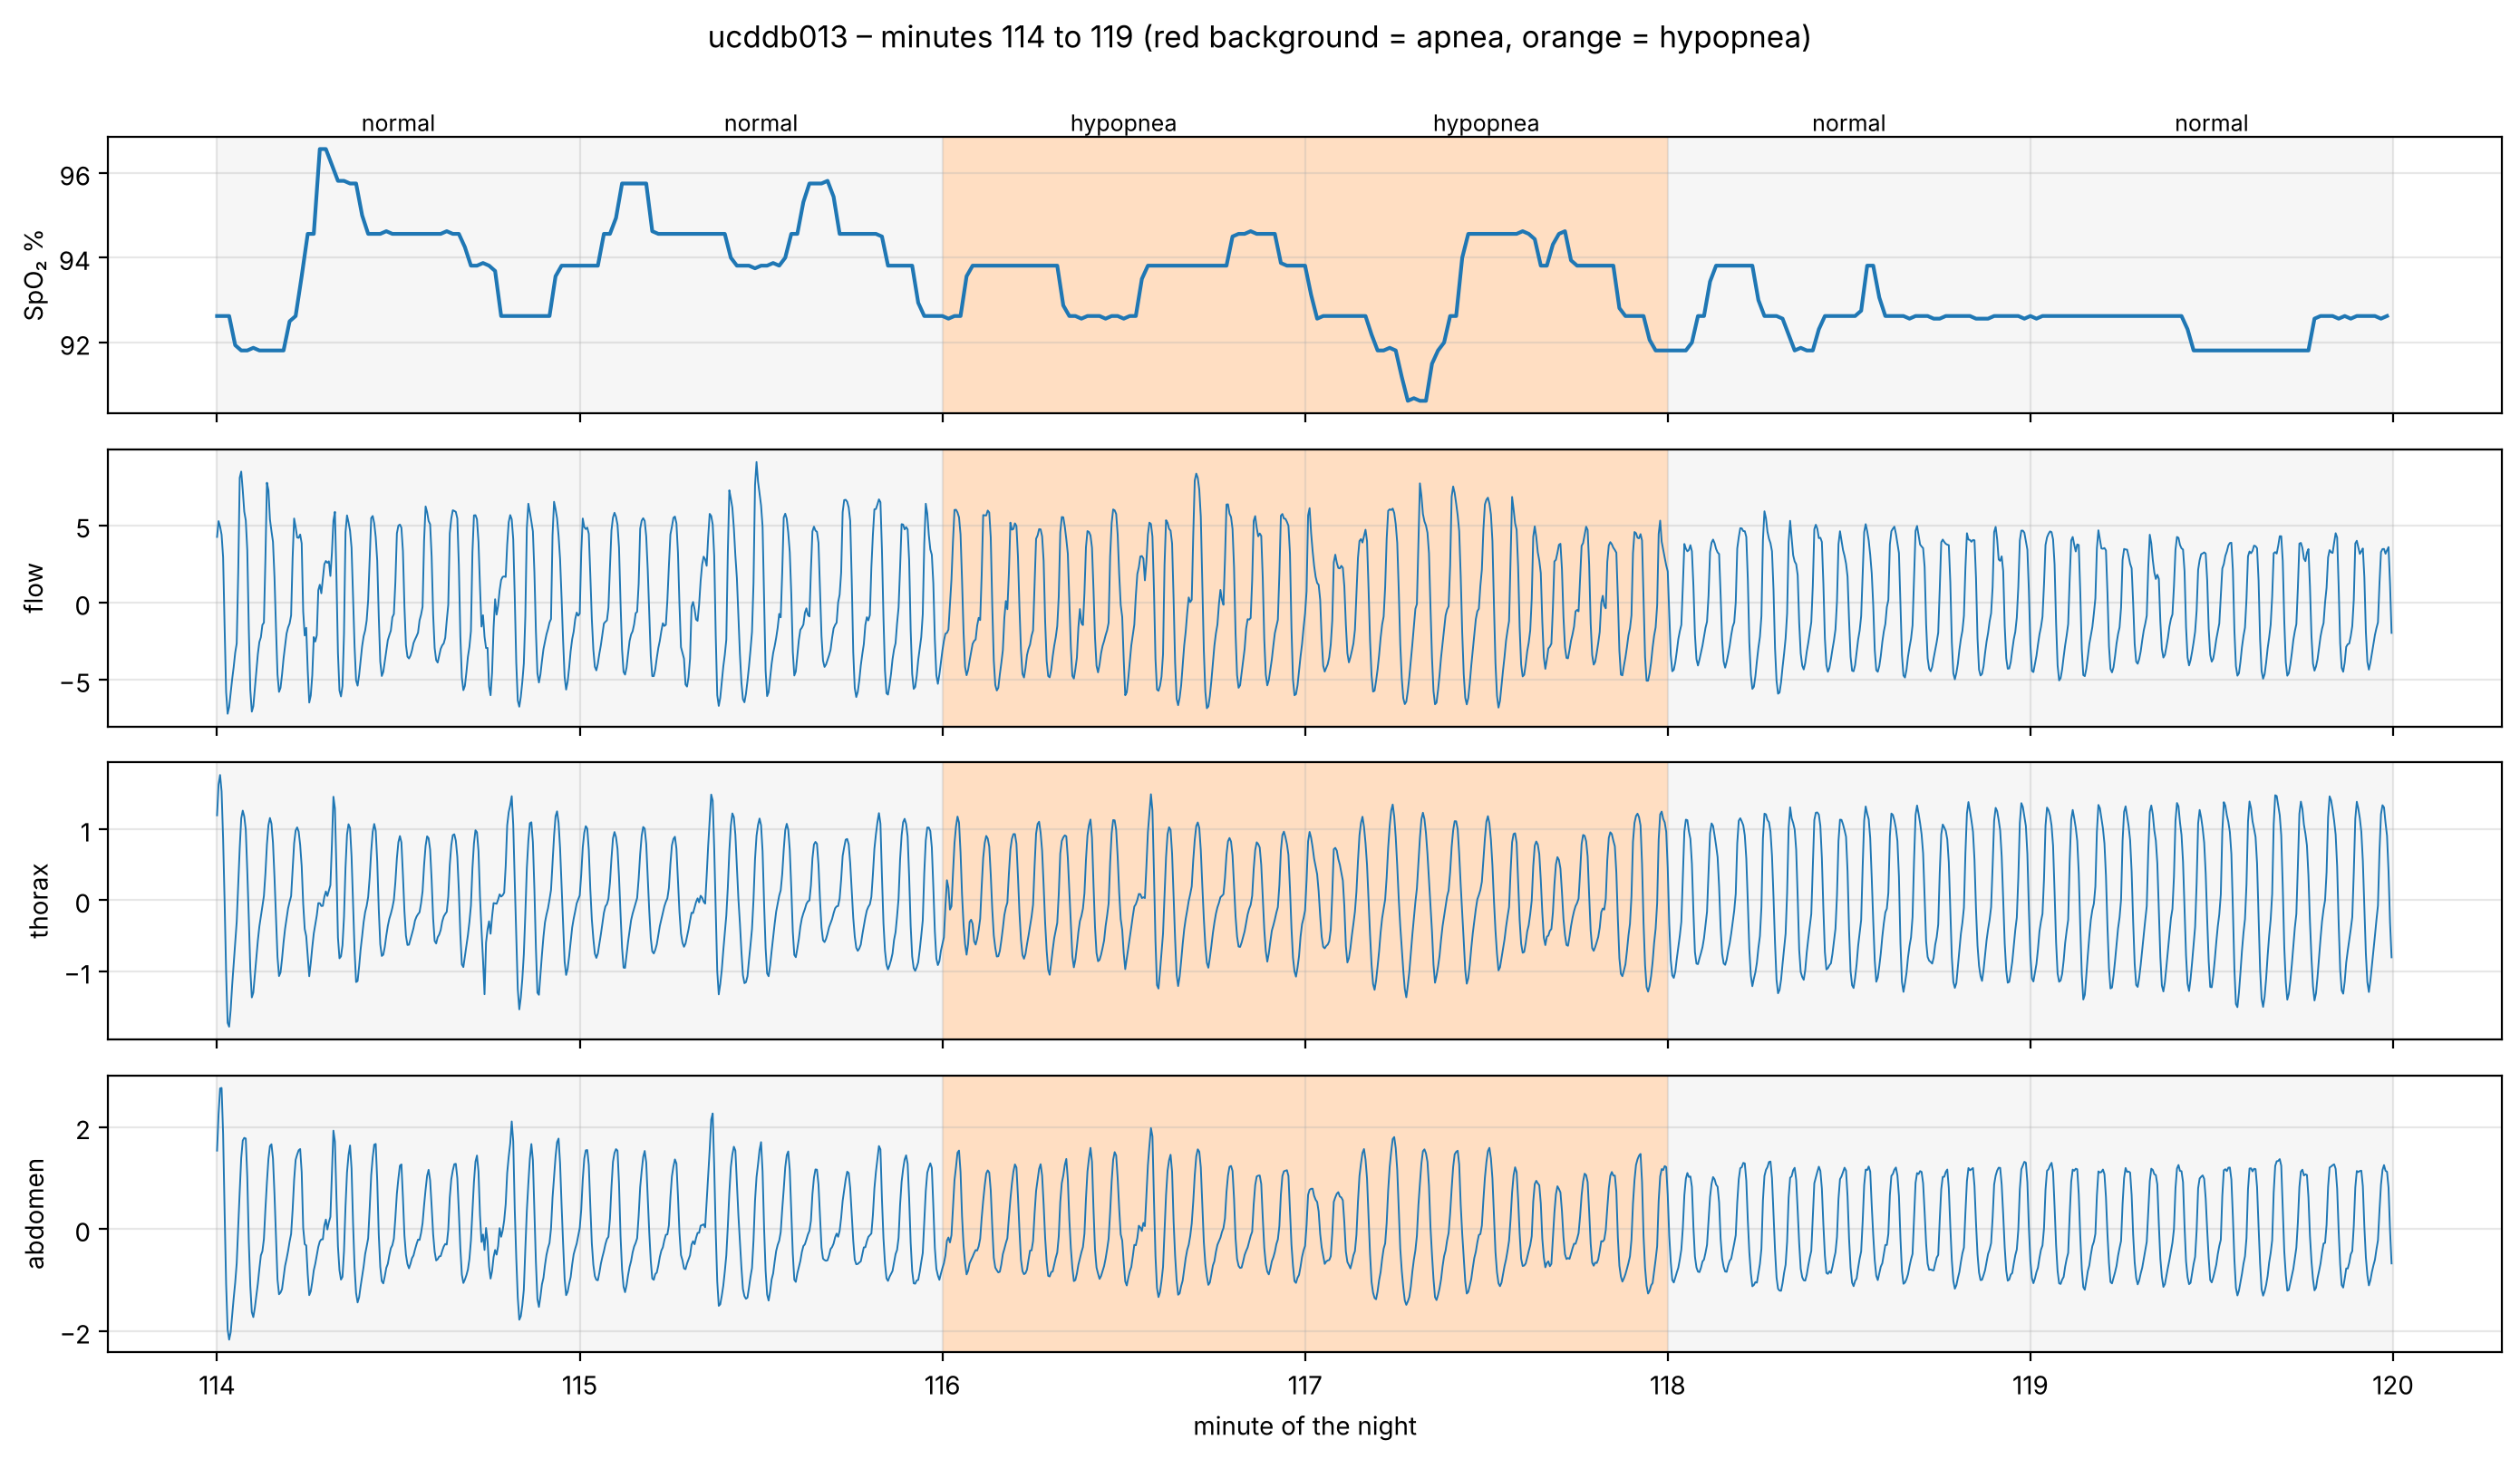

In [4]:
def first_run(event, length=2):
    ev = lab["event"]
    for m in ev.index:
        if all(ev.get(m + i) == event for i in range(length)):
            return m
    return int(ev.index[len(ev) // 2])

def zoom(start, n=6, title=""):
    s1, s4 = slice(start * 60, (start + n) * 60), slice(start * 240, (start + n) * 240)
    t1 = np.arange(start * 60, (start + n) * 60) / 60
    t4 = np.arange(start * 240, (start + n) * 240) / 240
    fig, ax = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
    ax[0].plot(t1, sig["spo2"][s1]); ax[0].set_ylabel("SpO₂ %")
    for a, k in zip(ax[1:], ["flow", "thorax", "abdomen"]):
        a.plot(t4, sig[k][s4], lw=0.7); a.set_ylabel(k)
    for m in range(start, start + n):
        ev = lab["event"].get(m, "unknown")
        for a in ax:
            a.axvspan(m, m + 1, color=colors.get(ev, "white"), alpha=0.25, lw=0)
        ax[0].text(m + 0.5, ax[0].get_ylim()[1], ev, ha="center", va="bottom", fontsize=9)
    ax[-1].set_xlabel("minute of the night")
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

has_apnea = (lab["event"] == "apnea").any()
ZOOM = max(first_run("apnea" if has_apnea else "hypopnea") - 2, 0)
zoom(ZOOM, title=f"{NIGHT} – minutes {ZOOM} to {ZOOM+5} (red background = apnea, orange = hypopnea)")

## 2. device-simulator → topic `raw-signals`

The device-simulator is not written yet (empty folder). It must replay a night and send **one message per
minute** to `raw-signals`, in the format of `kafka/schemas/raw-signals-value.schema.json`.
We do the same here with a small function and check that the messages match the schema.
Sensor gaps (NaN) become `null` in JSON.

In [5]:
from jsonschema import Draft202012Validator
RAW_SCHEMA = Draft202012Validator(json.loads((ROOT / "kafka/schemas/raw-signals-value.schema.json").read_text()))

def raw_messages(night_id, patient_id=None):
    s = np.load(DATA / "signals" / f"{night_id}.npz")
    n = len(s["spo2"]) // 60
    clean = lambda a: [None if np.isnan(v) else round(float(v), 3) for v in a]
    start = datetime(2026, 11, 20, 22, 0)
    for m in range(n):
        yield {
            "patient_id": patient_id or night_id, "night_id": night_id, "source": "ucddb",
            "minute": m, "is_last": m == n - 1,
            "sent_at": (start + timedelta(minutes=m)).isoformat() + "+00:00",
            "spo2": clean(s["spo2"][m*60:(m+1)*60]),
            "flow": clean(s["flow"][m*240:(m+1)*240]),
            "thorax": clean(s["thorax"][m*240:(m+1)*240]),
            "abdomen": clean(s["abdomen"][m*240:(m+1)*240]),
        }

raw = list(raw_messages(NIGHT))
errors = sum(1 for r in raw if list(RAW_SCHEMA.iter_errors(r)))
print(f"{len(raw)} raw-signals messages, {errors} schema error(s)")
print(f"size of one message: {len(json.dumps(raw[0])):,} bytes")

# one message, shortened for display
short = {k: (v[:5] + ["…"] if isinstance(v, list) else v) for k, v in raw[ZOOM].items()}
print(json.dumps(short, indent=2, ensure_ascii=False))

405 raw-signals messages, 0 schema error(s)
size of one message: 6,063 bytes
{
  "patient_id": "ucddb013",
  "night_id": "ucddb013",
  "source": "ucddb",
  "minute": 114,
  "is_last": false,
  "sent_at": "2026-11-20T23:54:00+00:00",
  "spo2": [
    92.625,
    92.625,
    92.625,
    91.938,
    91.812,
    "…"
  ],
  "flow": [
    4.242,
    5.266,
    4.914,
    4.387,
    2.932,
    "…"
  ],
  "thorax": [
    1.196,
    1.632,
    1.765,
    1.532,
    0.868,
    "…"
  ],
  "abdomen": [
    1.536,
    2.252,
    2.754,
    2.764,
    1.866,
    "…"
  ]
}


## 2b. The data **before** `features.py`: what `add_minute` receives

The detector does not give the JSON message to `features.py` directly. It first converts it with
`D.to_array(...)` (in `detector.py`):

- JSON lists become **numpy arrays** (`float32`)
- `null` (sensor off) becomes **NaN**
- a minute that is too short (the last one of the night) is filled up: NaN for SpO₂, mirrored for breathing
  (a flat line would look like an apnea)

Result: **4 arrays per minute**, always the same size. This is **all** that `features.py` sees:
no label, no time, no patient name.

In [6]:
M = ZOOM + 2                         # a minute with an event (see the zoom in part 1)
r = raw[M]
spo2    = D.to_array(r["spo2"], 60)
flow    = D.to_array(r["flow"], 240)
thorax  = D.to_array(r["thorax"], 240)
abdomen = D.to_array(r["abdomen"], 240)

print(f"minute {M} of {NIGHT}  (doctors' label: {lab['event'].get(M)}, which features.py does NOT see)\n")
for name, a, hz in [("spo2", spo2, 1), ("flow", flow, 4), ("thorax", thorax, 4), ("abdomen", abdomen, 4)]:
    print(f"{name:8s} shape={a.shape}  dtype={a.dtype}  {hz} Hz   "
          f"min={np.nanmin(a):8.2f}  max={np.nanmax(a):8.2f}  mean={np.nanmean(a):8.2f}  NaN={int(np.isnan(a).sum())}")

minute 116 of ucddb013  (doctors' label: hypopnea, which features.py does NOT see)

spo2     shape=(60,)  dtype=float32  1 Hz   min=   92.56  max=   94.62  mean=   93.57  NaN=0
flow     shape=(240,)  dtype=float32  4 Hz   min=   -6.83  max=    8.34  mean=   -0.07  NaN=0
thorax   shape=(240,)  dtype=float32  4 Hz   min=   -1.24  max=    1.49  mean=   -0.02  NaN=0
abdomen  shape=(240,)  dtype=float32  4 Hz   min=   -1.33  max=    1.98  mean=   -0.01  NaN=0


### The raw values, second by second

SpO₂ has **1 value per second**, breathing **4 values per second** (one every 0.25 s).
The table below shows the first 15 seconds of the minute, one row per second.
Note: `flow`, `thorax` and `abdomen` are in **raw device units** (not litres, not cm). That is why
`features.py` never looks at absolute values, only at ratios.

In [7]:
sec = pd.DataFrame({"second": np.arange(60), "spo2 (%)": np.round(spo2.astype(float), 2)})
for name, a in [("flow", flow), ("thorax", thorax), ("abdomen", abdomen)]:
    q = a.reshape(60, 4)                     # 60 seconds x 4 values
    sec[f"{name} (4 values)"] = [" ".join(f"{v:6.2f}" for v in row) for row in q]
sec.set_index("second").head(15)

,spo2 (%),flow (4 values),thorax (4 values),abdomen (4 values)
second,,,,
0,92.62,-3.11 -2.47 -2.01 -1.96,-0.61 -0.52 -0.08 0.28,-0.77 -0.67 -0.52 -0.23
1,92.56,-1.75 -0.17 1.50 3.95,0.18 -0.13 -0.08 0.38,-0.16 -0.26 -0.12 0.43
2,92.62,5.99 6.00 5.82 5.51,0.80 1.04 1.18 1.10,0.96 1.21 1.50 1.54
3,92.62,4.41 1.44 -1.91 -4.16,0.68 0.08 -0.34 -0.62,1.12 0.25 -0.32 -0.66
4,93.56,-4.70 -4.36 -3.75 -3.19,-0.77 -0.62 -0.30 -0.27,-0.89 -0.82 -0.67 -0.60
5,93.81,-2.67 -2.48 -2.38 -1.49,-0.33 -0.58 -0.62 -0.54,-0.54 -0.47 -0.41 -0.42
6,93.81,-0.99 -1.13 1.80 5.66,-0.42 -0.26 0.19 0.60,-0.34 -0.19 0.22 0.56
7,93.81,5.64 5.63 5.95 5.82,0.81 0.91 0.87 0.76,0.85 1.09 1.15 1.11
8,93.81,4.20 -0.20 -3.73 -5.32,0.36 -0.13 -0.49 -0.67,0.75 0.05 -0.56 -0.75


### One minute as a picture, with the 10 s windows

`features.py` cuts the breathing into **6 windows of 10 s** (40 values each) and measures the amplitude of each
window (95th percentile − 5th percentile). The grey bands show these windows; the number above is the
flow amplitude in that window.

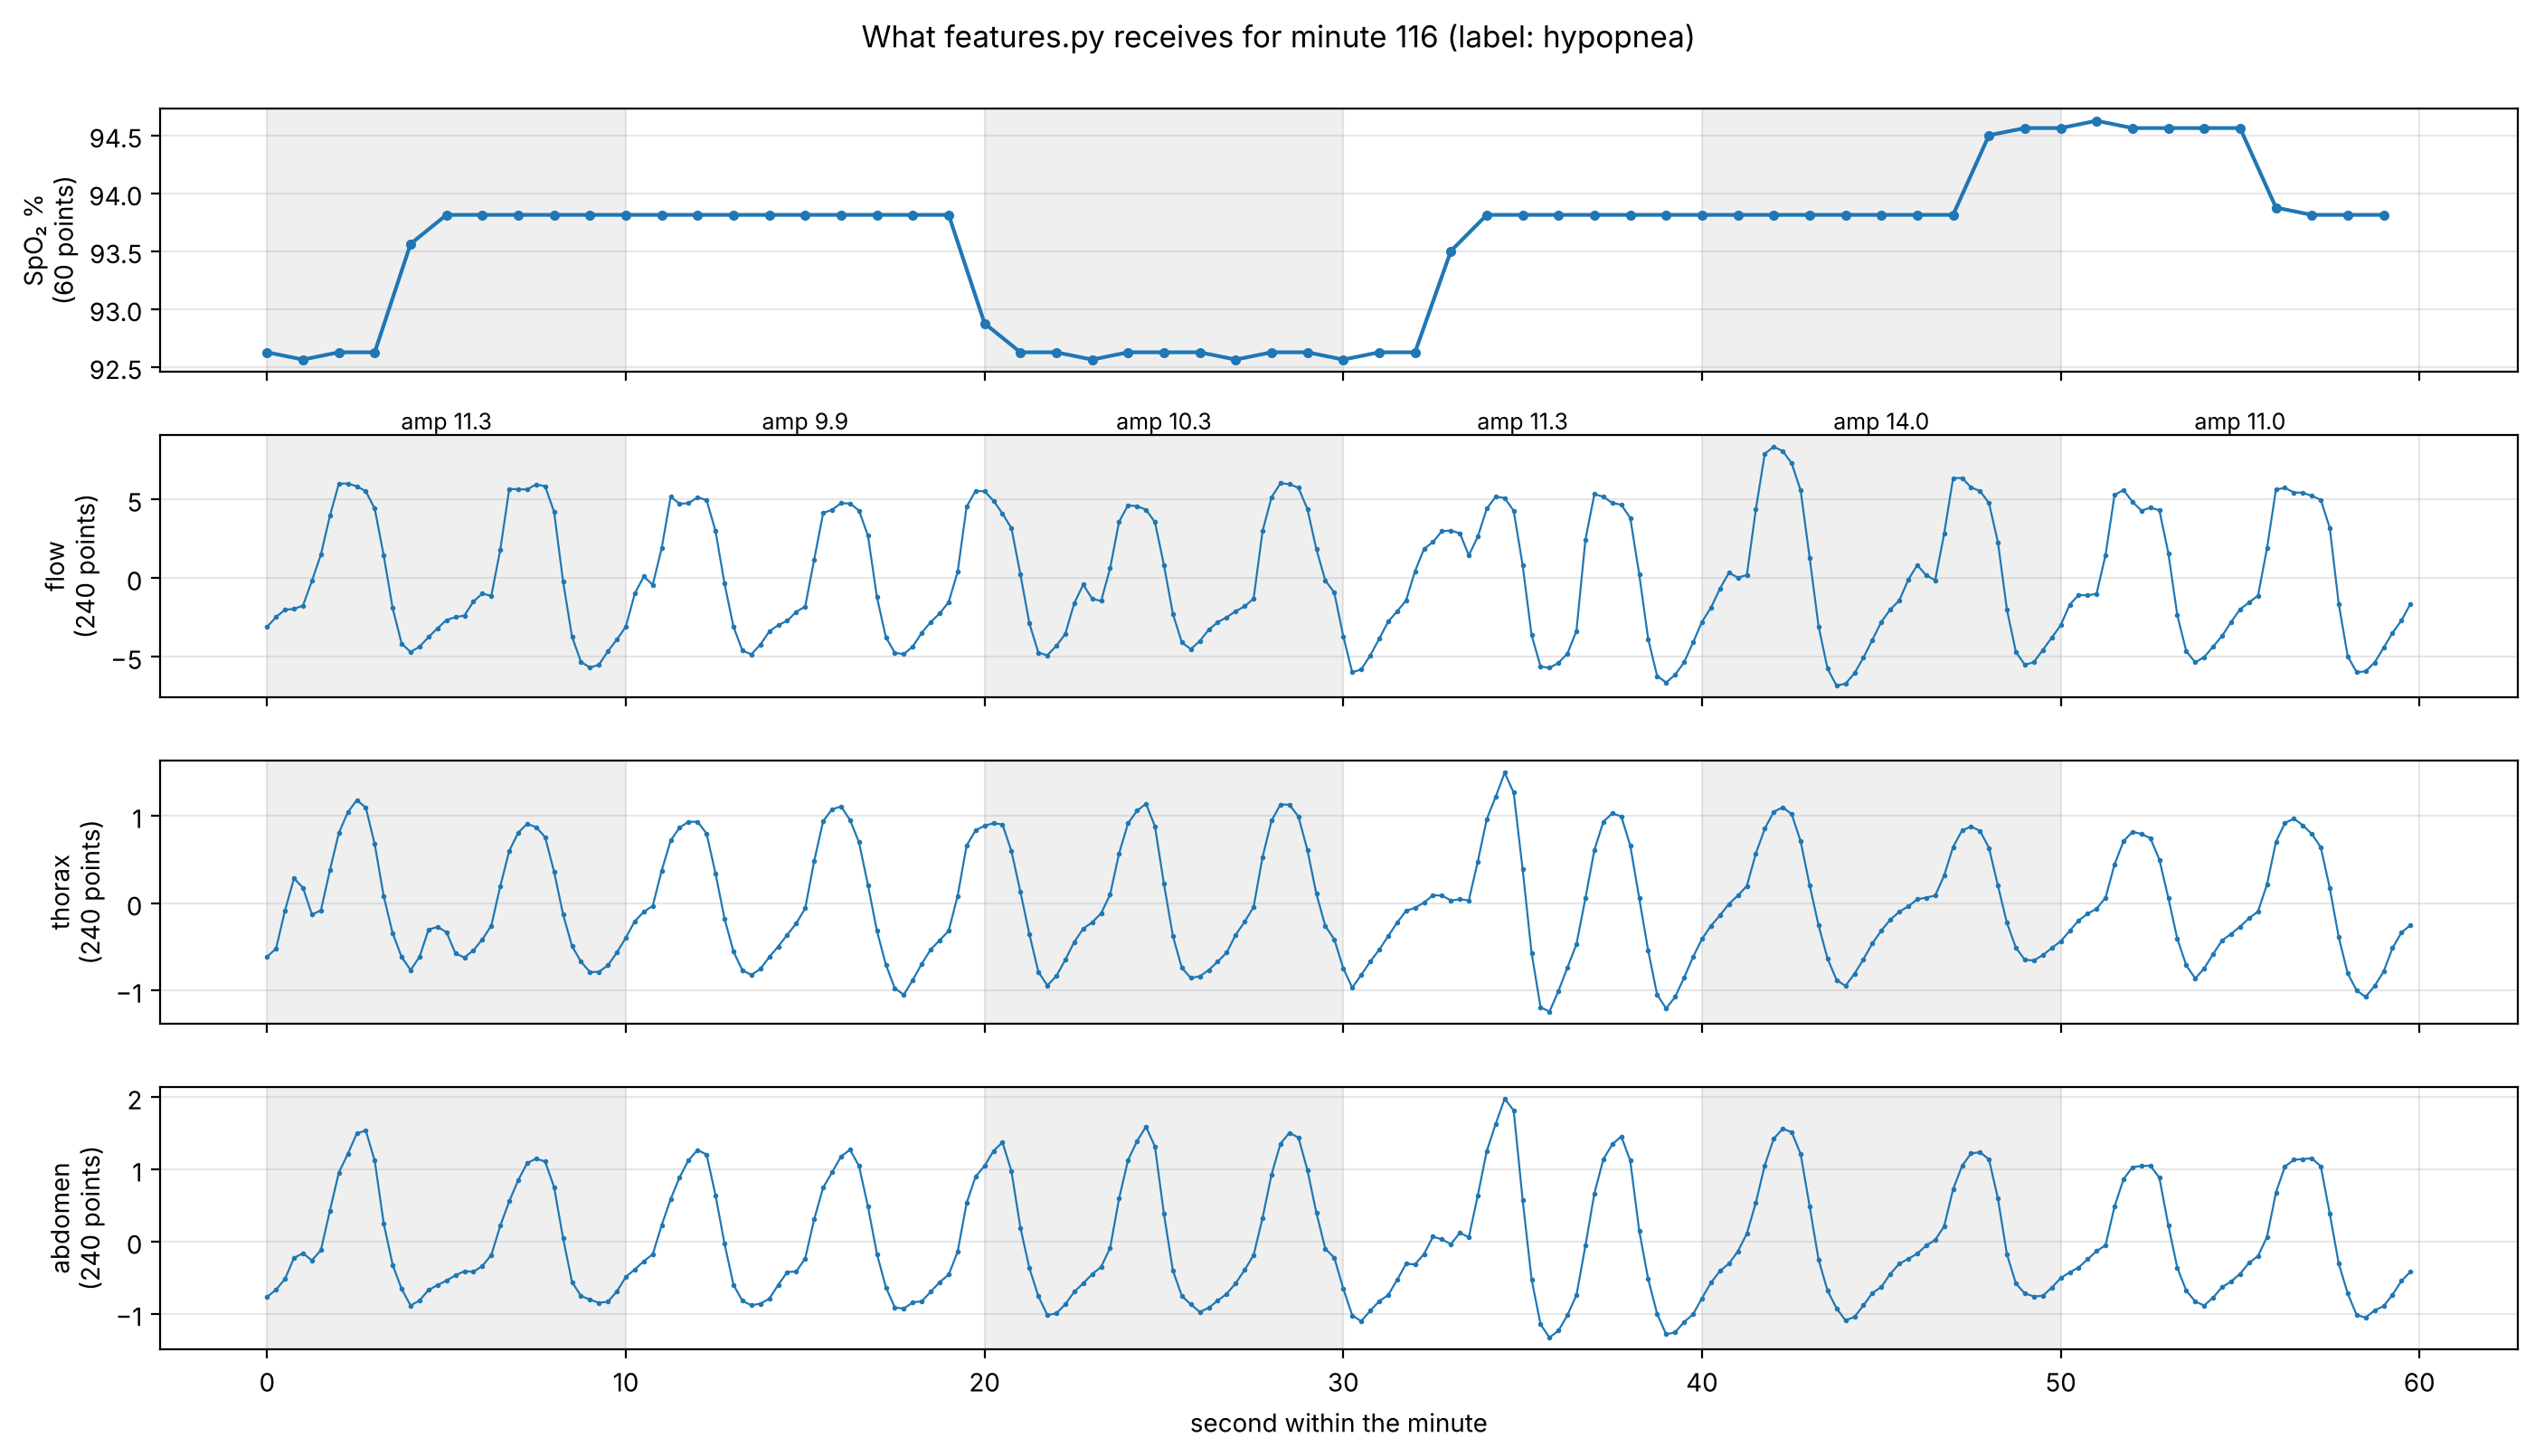

In [8]:
t1, t4 = np.arange(60), np.arange(240) / 4
per_window, per_second = F._amplitudes(flow)
fig, ax = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
ax[0].plot(t1, spo2, "o-", ms=3); ax[0].set_ylabel("SpO₂ %\n(60 points)")
for a, (name, x) in zip(ax[1:], [("flow", flow), ("thorax", thorax), ("abdomen", abdomen)]):
    a.plot(t4, x, ".-", ms=2, lw=0.8); a.set_ylabel(f"{name}\n(240 points)")
for a in ax:
    for w in range(0, 60, 20):
        a.axvspan(w, w + 10, color="grey", alpha=0.12, lw=0)
for i, amp in enumerate(per_window):
    ax[1].text(i * 10 + 5, ax[1].get_ylim()[1], f"amp {amp:.1f}", ha="center", va="bottom", fontsize=9)
ax[-1].set_xlabel("second within the minute"); ax[-1].set_xticks(range(0, 61, 10))
fig.suptitle(f"What features.py receives for minute {M} (label: {lab['event'].get(M)})", y=1.0)
plt.tight_layout(); plt.show()

### Sensor gaps (NaN)

Over the whole night: how many values are missing? In `data/02_clean.py`, SpO₂ gaps shorter than 10 s are
already filled with a straight line; longer ones stay NaN, and `features.py` counts them in `spo2_missing`.

In [9]:
miss = pd.DataFrame({
    k: {"values": len(sig[k]), "NaN": int(np.isnan(sig[k]).sum()),
        "% NaN": round(100 * np.isnan(sig[k]).mean(), 2),
        "minutes with at least 1 NaN": int(np.isnan(sig[k][: len(sig[k]) // (60 if k == 'spo2' else 240) * (60 if k == 'spo2' else 240)])
                                           .reshape(-1, 60 if k == "spo2" else 240).any(axis=1).sum())}
    for k in ["spo2", "flow", "thorax", "abdomen"]}).T
miss.astype({"values": int, "NaN": int, "minutes with at least 1 NaN": int})

,values,NaN,% NaN,minutes with at least 1 NaN
spo2,24300,44,0.18,1
flow,97200,0,0.00,0
thorax,97200,0,0.00,0
abdomen,97200,0,0.00,0


**In short:** before `features.py`, one minute = **780 raw numbers** (60 + 3 × 240), in units that depend on
the device. After `features.py`, the same minute = **42 numbers that can be compared between patients**
(ratios, seconds below a threshold, oxygen drop…). That is the next part.

## 3. `features.py`: one minute → 42 numbers

We create **one** `NightFeatures` for the night and give it the minutes one by one, like the live detector.
It remembers the last 5 minutes (the patient's "baseline") and returns a dictionary of 42 features:
21 for the current minute and the same 21 for the previous minute (`prev_*`).

In [10]:
nf = F.NightFeatures()
rows = []
for r in raw:
    rows.append(nf.add_minute(D.to_array(r["spo2"], 60), D.to_array(r["flow"], 240),
                              D.to_array(r["thorax"], 240), D.to_array(r["abdomen"], 240)))
feat = pd.DataFrame(rows)
feat["event"] = lab["event"].reindex(feat.index).fillna("unknown")
print(feat.shape, "->", len(F.FEATURES), "features + the event column (to compare)")
feat[F.CURRENT + ["event"]].iloc[ZOOM:ZOOM + 6].round(2)

(405, 43) -> 42 features + the event column (to compare)


,spo2_mean,spo2_min,spo2_drop,spo2_slope,spo2_s_below_3,spo2_s_below_4,spo2_missing,flow_amp_ratio_min,flow_amp_ratio_mean,flow_s_below_10,flow_s_below_70,thorax_amp_ratio_min,thorax_amp_ratio_mean,thorax_s_below_10,thorax_s_below_70,abdomen_amp_ratio_min,abdomen_amp_ratio_mean,abdomen_s_below_10,abdomen_s_below_70,flow_breaths,thorax_abdomen_corr,event
114,93.74,91.81,3.94,0.57,23.0,0.0,0.0,0.77,0.93,0.0,0.0,0.72,1.05,0.0,0.0,0.77,1.16,0.0,0.0,15.0,0.97,normal
115,94.42,92.62,3.12,-0.94,3.0,0.0,0.0,0.83,0.94,0.0,0.0,0.77,0.91,0.0,0.0,0.76,0.93,0.0,3.0,14.0,0.98,normal
116,93.57,92.56,3.19,1.09,16.0,0.0,0.0,0.84,0.96,0.0,0.0,0.91,0.99,0.0,0.0,0.78,0.87,0.0,0.0,15.0,0.98,hypopnea
117,93.06,90.62,4.00,1.37,6.0,0.0,0.0,0.72,0.95,0.0,0.0,0.80,1.08,0.0,0.0,0.67,0.98,0.0,6.0,14.0,0.97,hypopnea
118,92.69,91.81,2.75,-0.13,0.0,0.0,0.0,0.73,0.82,0.0,0.0,1.09,1.22,0.0,0.0,0.82,0.91,0.0,0.0,14.0,0.98,normal
119,92.34,91.81,2.75,-0.39,0.0,0.0,0.0,0.70,0.79,0.0,0.0,1.19,1.28,0.0,0.0,0.91,0.97,0.0,0.0,14.0,0.98,normal


### Do the features separate the classes?

Mean of a few features per type of minute. If `features.py` does its job, apnea minutes should have many
seconds of almost flat breathing (`flow_s_below_10`), hypopneas many seconds below 70 % (`flow_s_below_70`)
and an oxygen drop (`spo2_drop`) — often only visible in the **next** minute (`prev_…` vs current).

In [11]:
cols = ["flow_s_below_10", "flow_s_below_70", "flow_amp_ratio_min", "spo2_drop", "spo2_s_below_3",
        "thorax_abdomen_corr", "flow_breaths"]
feat[feat.event != "unknown"].groupby("event")[cols].mean().round(2)

,flow_s_below_10,flow_s_below_70,flow_amp_ratio_min,spo2_drop,spo2_s_below_3,thorax_abdomen_corr,flow_breaths
event,,,,,,,
hypopnea,0.00,4.10,0.76,4.96,23.49,0.90,15.13
normal,0.25,3.18,0.87,2.67,6.67,0.83,14.39


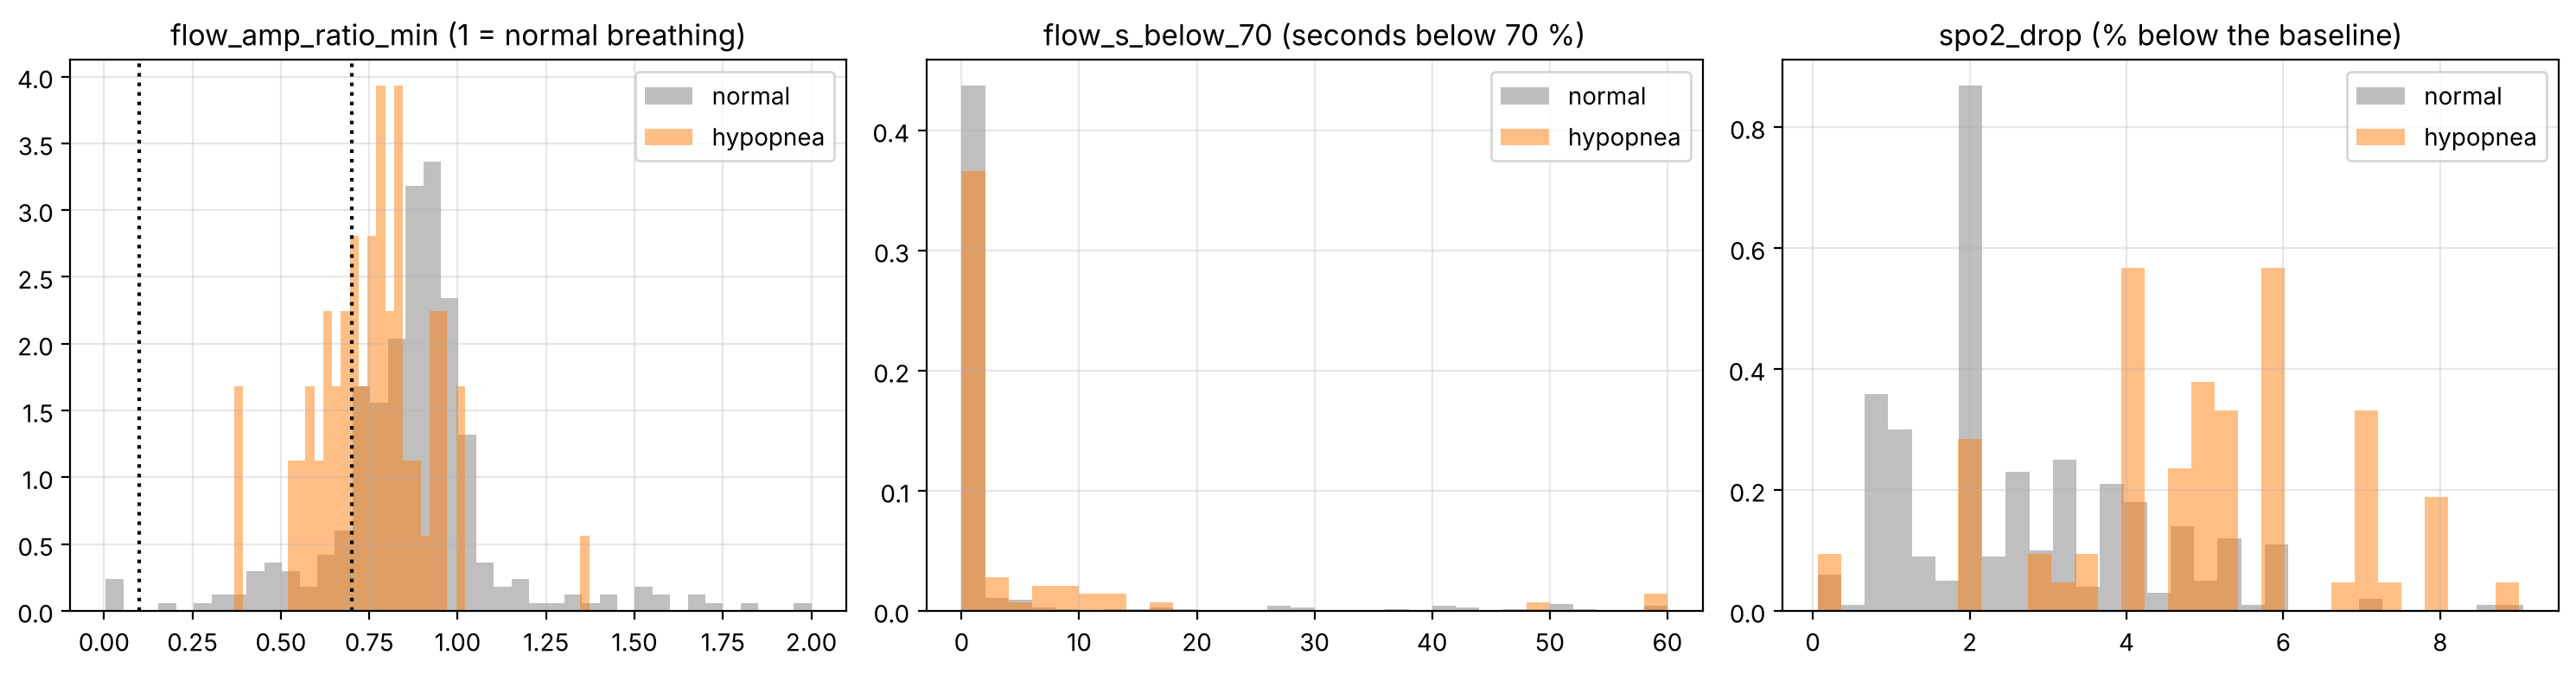

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for e in ["normal", "hypopnea", "apnea"]:
    d = feat[feat.event == e]
    if d.empty:
        continue                      # some nights have no apnea, only hypopneas
    ax[0].hist(d["flow_amp_ratio_min"].clip(0, 2), bins=40, alpha=0.5, density=True, label=e, color=colors[e] if e != "normal" else "grey")
    ax[1].hist(d["flow_s_below_70"], bins=30, alpha=0.5, density=True, label=e, color=colors[e] if e != "normal" else "grey")
    ax[2].hist(d["spo2_drop"].clip(0, 15), bins=30, alpha=0.5, density=True, label=e, color=colors[e] if e != "normal" else "grey")
ax[0].set_title("flow_amp_ratio_min (1 = normal breathing)")
ax[0].axvline(0.1, color="k", ls=":"); ax[0].axvline(0.7, color="k", ls=":")
ax[1].set_title("flow_s_below_70 (seconds below 70 %)")
ax[2].set_title("spo2_drop (% below the baseline)")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

### The baseline follows the patient

`normal` = median of the amplitudes of the last 5 minutes. The chart shows the amplitude of each 10 s window
of the flow, and the baseline that slowly follows it. The **ratio** (amplitude / baseline) is what the model sees.

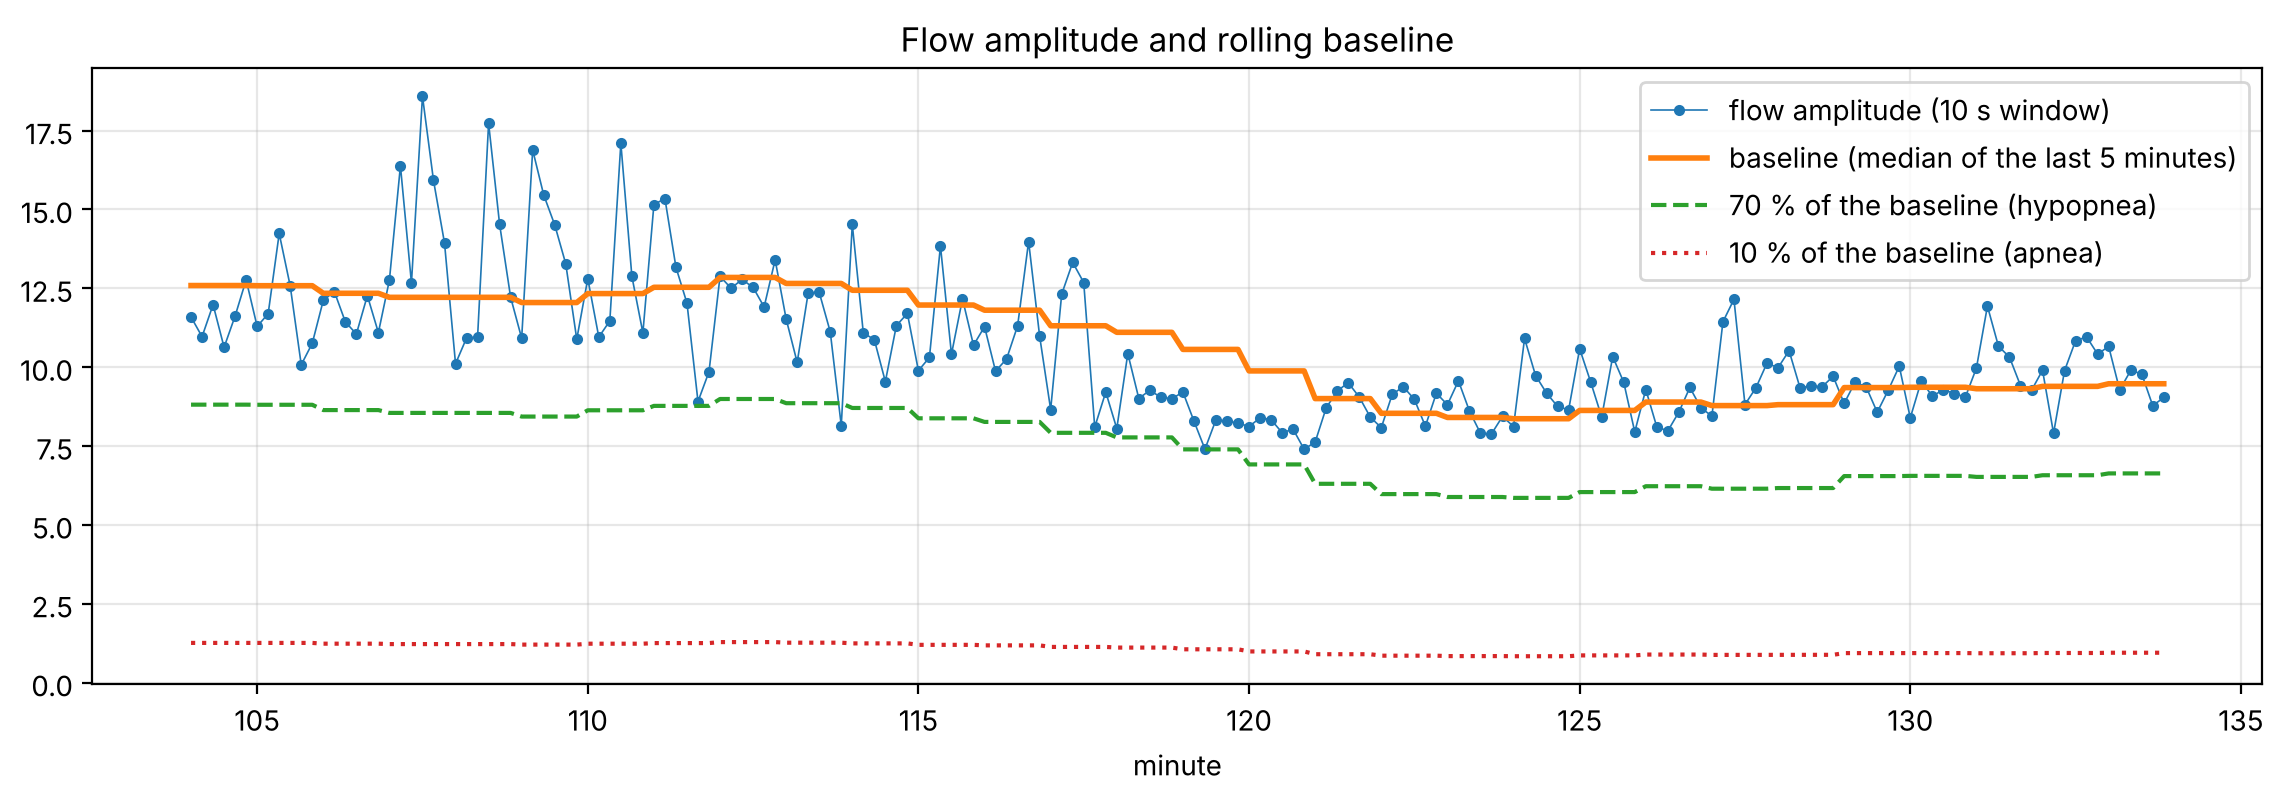

In [13]:
nf2 = F.NightFeatures()
amps, bases = [], []
for r in raw:
    per_window, _ = F._amplitudes(D.to_array(r["flow"], 240))
    hist = nf2.amp_hist["flow"]
    bases += [np.median(hist) if hist else np.median(per_window)] * len(per_window)
    amps += list(per_window)
    nf2.add_minute(D.to_array(r["spo2"], 60), D.to_array(r["flow"], 240),
                   D.to_array(r["thorax"], 240), D.to_array(r["abdomen"], 240))
t = np.arange(len(amps)) / 6   # 6 windows of 10 s per minute
sel = (t >= ZOOM - 10) & (t < ZOOM + 20)
plt.plot(t[sel], np.array(amps)[sel], ".-", lw=0.6, label="flow amplitude (10 s window)")
plt.plot(t[sel], np.array(bases)[sel], lw=2, label="baseline (median of the last 5 minutes)")
plt.plot(t[sel], 0.7 * np.array(bases)[sel], "--", label="70 % of the baseline (hypopnea)")
plt.plot(t[sel], 0.1 * np.array(bases)[sel], ":", label="10 % of the baseline (apnea)")
plt.xlabel("minute"); plt.legend(); plt.title("Flow amplitude and rolling baseline"); plt.show()

## 4. model-trainer: train both models

Exactly the steps of `train.py`, without the database and without CodeCarbon:

1. features of all `train` nights (20 UCDDB nights), with the same `features.py`
2. **accurate** model (gradient boosting, 3 classes) and **fast** model (logistic regression, very little CPU)
3. test on the held-out Apnea-ECG nights (`test`): their experts only scored "apnea or hypopnea",
   so the test is binary (F1 of the "event" class)
4. save to `models/model.joblib` and `models/model-fast.joblib`, in the same format as `train.py`,
   so the detector can load them

⏱ This cell takes about one minute.

In [14]:
splits_map = TR.load_splits(DATA)
labels_map = TR.load_labels(DATA)
train_n = sorted(n for n, s in splits_map.items() if s == "train")
test_n = sorted(n for n, s in splits_map.items() if s == "test")
demo_n = sorted(n for n, s in splits_map.items() if s == "demo")
print("train:", len(train_n), " test:", len(test_n), " demo:", demo_n)

t0 = time.time()
X_train, y_train = TR.build_set(DATA, train_n, labels_map, TR.TRAIN_LABEL)
X_test, y_test = TR.build_set(DATA, test_n, labels_map, TR.TEST_LABEL)
print(f"features built in {time.time()-t0:.0f} s: train {X_train.shape}, test {X_test.shape}")
print("training minutes per class:", dict(zip(TR.CLASSES, np.bincount(y_train, minlength=3).tolist())))

bundles = {}
for kind in ["accurate", "fast"]:
    t0 = time.time()
    model = TR.make_model(kind).fit(X_train, y_train)
    metrics = TR.evaluate(model, X_test, y_test)
    bundles[kind] = {"model": model, "features": F.FEATURES, "classes": TR.CLASSES,
                     "version": f"{kind}-notebook", "metrics": metrics}
    out = TR.DEFAULT_OUT[kind]; out.parent.mkdir(exist_ok=True)
    import joblib; joblib.dump(bundles[kind], out)
    print(f"{kind:8s} trained in {time.time()-t0:4.0f} s   F1 {metrics['f1']:.3f}  "
          f"precision {metrics['precision']:.3f}  recall {metrics['recall']:.3f}  -> {out.relative_to(ROOT)}")

train: 20  test: 8  demo: ['ucddb010', 'ucddb013', 'ucddb017', 'ucddb018', 'ucddb025']


features built in 83 s: train (8250, 42), test (3875, 42)
training minutes per class: {'normal': 6113, 'apnea': 436, 'hypopnea': 1701}


accurate trained in    5 s   F1 0.906  precision 0.850  recall 0.971  -> models/model.joblib
fast     trained in    0 s   F1 0.882  precision 0.795  recall 0.991  -> models/model-fast.joblib


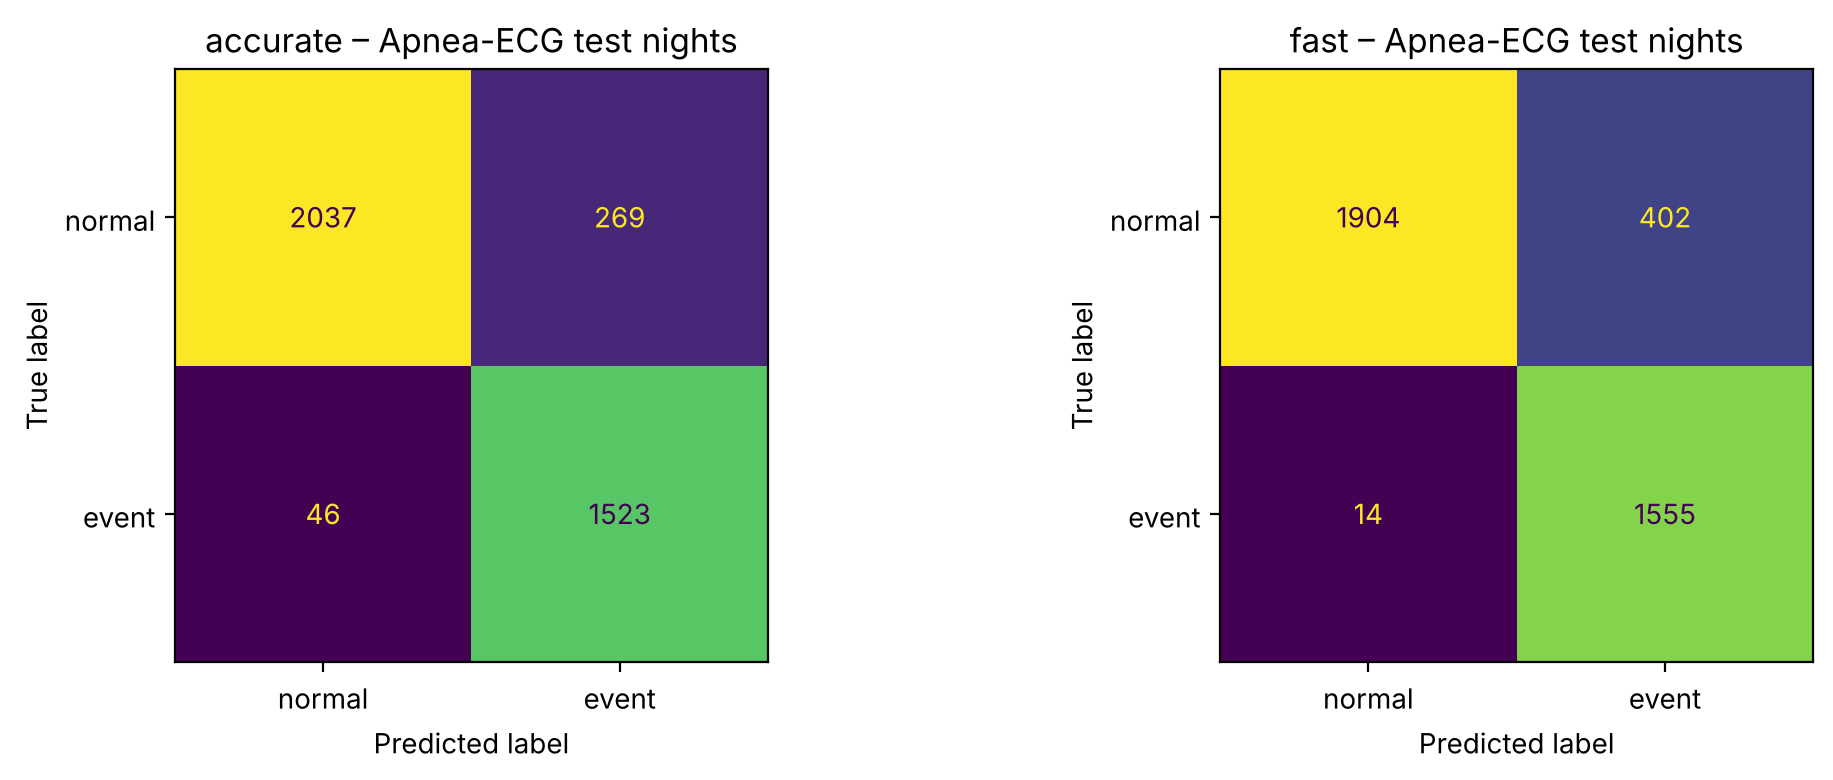

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, kind in zip(ax, ["accurate", "fast"]):
    pred = (bundles[kind]["model"].predict(X_test) != 0).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["normal", "event"]).plot(ax=a, colorbar=False)
    a.set_title(f"{kind} – Apnea-ECG test nights"); a.grid(False)
plt.tight_layout(); plt.show()

### F1 gate (`gate.py`)

A new model is only used if its F1 is **≥ 0.80** and **not worse than the model in use**.
We try `G.decide` in a few situations.

In [16]:
f1 = bundles["accurate"]["metrics"]["f1"]
for current in [None, f1 - 0.02, f1 + 0.02]:
    ok, why = G.decide(f1, G.DEFAULT_THRESHOLD, current)
    print(("✅ approved" if ok else "❌ rejected").ljust(12), "|", why)
print(("✅ approved" if G.decide(0.75, 0.80)[0] else "❌ rejected").ljust(12), "|", G.decide(0.75, 0.80)[1])

✅ approved   | F1 0.906 >= threshold 0.80
✅ approved   | F1 0.906 >= threshold 0.80 and >= model in use (0.886)
❌ rejected   | F1 0.906 is worse than the model in use (0.926)
❌ rejected   | F1 0.750 is below the threshold 0.80


## 5. apnea-detector

The detector has three loops. We replay them one by one.

### 5a. `alerts` loop (UC3): SpO₂ < 80 % → topic `alerts`

Never paused, not even in `high_carbon` (ADR 0002). For each minute, `alert_for` takes the lowest **valid** SpO₂
(values < 50 % are sensor artefacts) and creates a message if it is below 80 %.

In [17]:
alerts = [a for a in (D.alert_for(r) for r in raw) if a]
print(f"{len(alerts)} alerts in {len(raw)} minutes")
if alerts:
    print(json.dumps(alerts[0], indent=2))
    plt.plot(np.arange(len(sig["spo2"])) / 60, sig["spo2"], lw=0.4)
    plt.scatter([a["minute"] for a in alerts], [a["spo2_min"] for a in alerts], color="red", s=12, zorder=3, label="alert")
    plt.axhline(80, color="red", ls="--", lw=1); plt.xlabel("minute"); plt.ylabel("SpO₂ %"); plt.legend()
    plt.title("Minutes that trigger an alert"); plt.show()

0 alerts in 405 minutes


### 5b. `carbon` loop + carbon rule (UC5)

The detector reads the newest `carbon-signal` message and `decide(mode, time)` chooses
`accurate`, `fast` or `pause`. In `high_carbon` it waits (the minutes stay in Kafka) while 08:00 is far away,
then switches to the fast model when 2 h or less are left.

In [18]:
from zoneinfo import ZoneInfo
tz = ZoneInfo("Europe/Vienna")
hours = ["22:00", "00:00", "02:00", "04:00", "05:30", "06:00", "06:30", "07:30", "08:30"]
table = []
for h in hours:
    hh, mm = map(int, h.split(":"))
    now = datetime(2026, 11, 21, hh, mm, tzinfo=tz)
    table.append({"time": h, "low_carbon": D.decide("low_carbon", now), "high_carbon": D.decide("high_carbon", now)})
pd.DataFrame(table).set_index("time")

,low_carbon,high_carbon
time,,
22:00,accurate,pause
00:00,accurate,pause
02:00,accurate,pause
04:00,accurate,pause
05:30,accurate,pause
06:00,accurate,fast
06:30,accurate,fast
07:30,accurate,fast
08:30,accurate,pause


### 5c. `analysis` loop (UC2): `raw-signals` → `apnea-events`

We load the models like the detector does (`D.Model`, which checks that the feature order is right) and
give each minute to `Analyzer.process`. Result: **one `apnea-events` message per minute**.

We also simulate a carbon scenario: the night starts in `low_carbon` and switches to `high_carbon` in the middle.
With the real clock the detector would pause; here we show directly the "close to 08:00" case,
where it switches to the fast model.

In [19]:
accurate = D.Model(bundles["accurate"], D.ACCURATE)
fast = D.Model(bundles["fast"], D.FAST)

def run_detector(raw_msgs, switch_to_high_at=None, region="NO"):
    analyzer = D.Analyzer(accurate, fast, region=region)
    events = []
    for r in raw_msgs:
        high = switch_to_high_at is not None and r["minute"] >= switch_to_high_at
        carbon = {"mode": "high_carbon" if high else "low_carbon",
                  "carbon_intensity": 450.0 if high else 35.0, "region": region}
        action = D.FAST if high else D.ACCURATE      # = decide(...) when 08:00 is close
        msg = analyzer.process(r, action, carbon)
        if msg: events.append(msg)
    return events

events = run_detector(raw)
ev = pd.DataFrame(events)
print(f"{len(ev)} apnea-events messages")
print(json.dumps(events[-1], indent=2))
ev["event"].value_counts()

405 apnea-events messages
{
  "patient_id": "ucddb013",
  "night_id": "ucddb013",
  "minute": 404,
  "event": "hypopnea",
  "probability": 0.929,
  "model": "accurate",
  "model_version": "accurate-notebook",
  "carbon_mode": "low_carbon",
  "region": "NO",
  "is_last": true,
  "sent_at": "2026-11-22T12:11:49.686608+00:00",
  "kwh": 1.5351e-05,
  "gco2": 0.000537
}


event
normal      325
hypopnea     77
apnea         3
Name: count, dtype: int64

event     normal  hypopnea  apnea  All
true                                  
normal       296        35      3  334
hypopnea      29        42      0   71
apnea          0         0      0    0
unknown        0         0      0    0
All          325        77      3  405


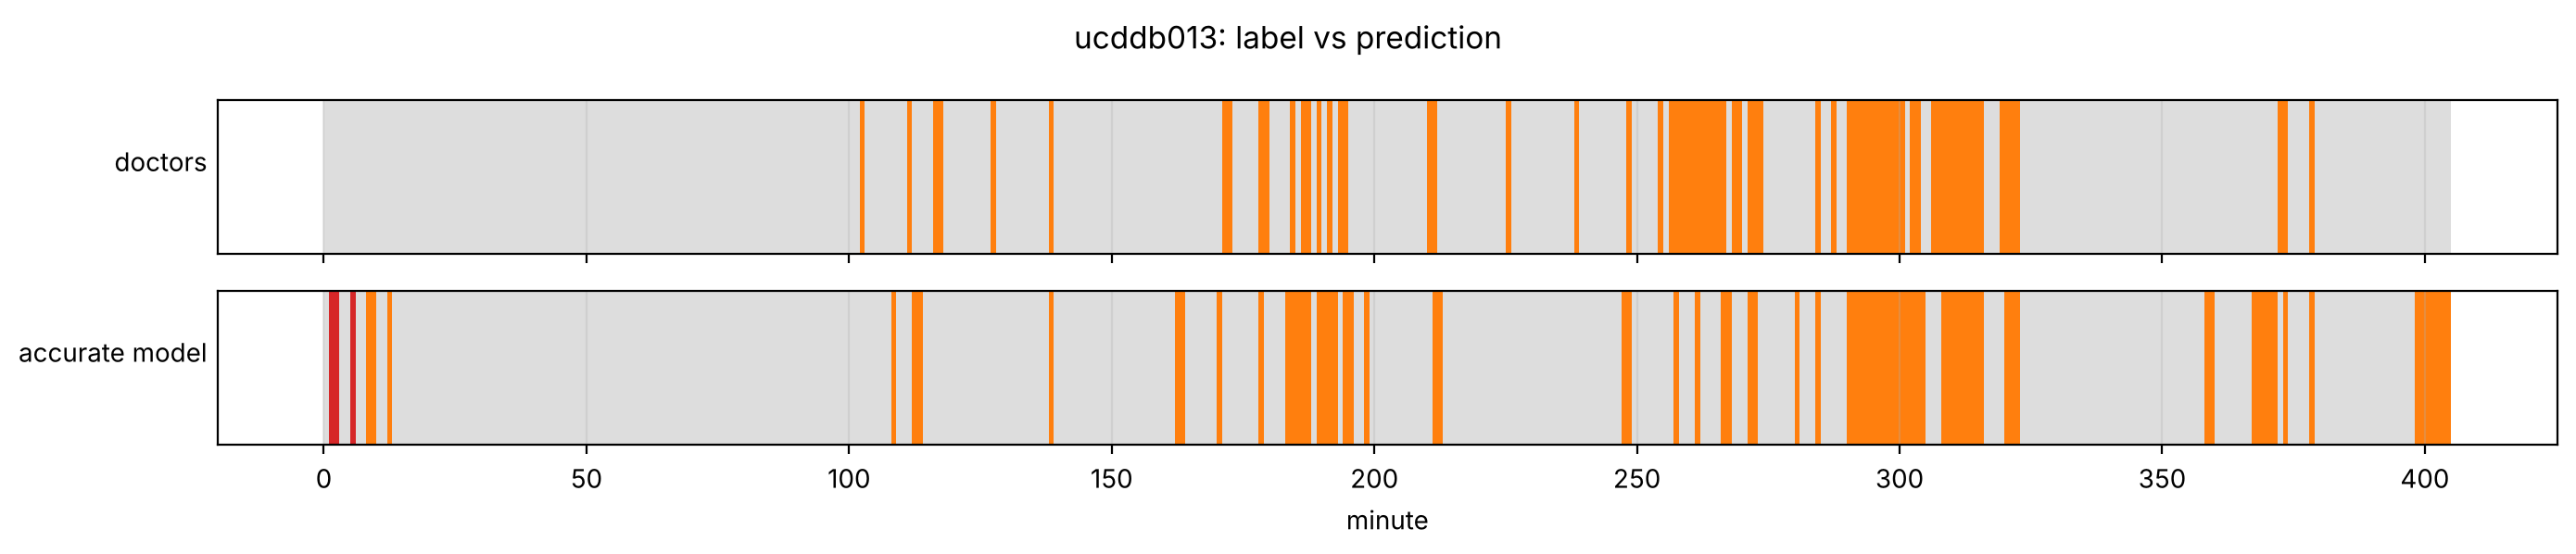

In [20]:
# prediction vs doctors' label, minute by minute
cmp = ev.set_index("minute")[["event", "probability"]].join(lab["event"].rename("true"))
order = ["normal", "hypopnea", "apnea"]
print(pd.crosstab(cmp["true"], cmp["event"], margins=True).reindex(index=order + ["unknown", "All"], columns=order + ["All"]).fillna(0).astype(int))

fig, ax = plt.subplots(2, 1, figsize=(14, 3), sharex=True)
for a, col, name in [(ax[0], "true", "doctors"), (ax[1], "event", "accurate model")]:
    for m, e in cmp[col].items():
        a.axvspan(m, m + 1, color=colors.get(e, "white"), lw=0)
    a.set_yticks([]); a.set_ylabel(name, rotation=0, ha="right")
ax[1].set_xlabel("minute"); fig.suptitle(f"{NIGHT}: label vs prediction"); plt.tight_layout(); plt.show()

In [21]:
# scenario: high_carbon from the middle of the night -> fast model for the rest
mid = len(raw) // 2
events_mix = run_detector(raw, switch_to_high_at=mid)
mix = pd.DataFrame(events_mix)
print(mix.groupby(["carbon_mode", "model"])["event"].value_counts().unstack(fill_value=0))
print("\nlast message (energy and CO₂ of the whole night):")
print({k: events_mix[-1][k] for k in ["model", "carbon_mode", "region", "kwh", "gco2"]})

event                 apnea  apnea_or_hypopnea  hypopnea  normal
carbon_mode model                                               
high_carbon fast          0                119         0      84
low_carbon  accurate      3                  0        23     176

last message (energy and CO₂ of the whole night):
{'model': 'fast', 'carbon_mode': 'high_carbon', 'region': 'NO', 'kwh': 1.2007e-05, 'gco2': 0.005403}


## 6. ahi-triage: `apnea-events` → AHI → `results` / `night-results`

`Triage.handle` receives the messages one by one. It counts each `(night_id, minute)` **only once**
(Kafka can deliver twice) and, at the `is_last` message, computes:

- **AHI** = minutes with an event / hours of recording
- **severity**: normal < 5 · mild 5–15 · moderate 15–30 · severe ≥ 30
- **deadline_met**: finished before 08:00 (with the demo clock)

In [22]:
triage = T.Triage(clock=T.Clock("06:30"))
result = None
for msg in events:
    out = triage.handle(msg)
    if out: result = out
print(json.dumps(result, indent=2))
print("\ntrue AHI (doctors' labels):", splits[NIGHT]["ahi"])

{
  "patient_id": "ucddb013",
  "night_id": "ucddb013",
  "ahi": 11.9,
  "severity": "mild",
  "event_count": 80,
  "apnea_count": 3,
  "hypopnea_count": 77,
  "minutes": 405,
  "model": "accurate",
  "model_version": "accurate-notebook",
  "carbon_mode": "low_carbon",
  "region": "NO",
  "kwh": 1.5351e-05,
  "gco2": 0.000537,
  "deadline_met": true,
  "finished_at": "2026-11-22T05:30:00.000469+00:00"
}

true AHI (doctors' labels): 15.7


In [23]:
# Kafka delivers "at least once": we send 50 duplicates, the result must not change
import random
random.seed(0)
dup = events[:-1] + random.sample(events[:-1], 50) + [events[-1]]
t2 = T.Triage(clock=T.Clock("06:30"))
res2 = [o for o in (t2.handle(m) for m in dup) if o][0]
print("AHI without duplicates:", result["ahi"], "| with 50 duplicates:", res2["ahi"])
print("a duplicate that arrives AFTER the night is finished is ignored:", t2.handle(events[3]))

# with the fast model we cannot tell apnea from hypopnea
t3 = T.Triage(clock=T.Clock("06:30"))
res_mix = [o for o in (t3.handle(m) for m in events_mix) if o][0]
print("\nnight finished with the fast model:", {k: res_mix[k] for k in ["ahi", "severity", "apnea_count", "hypopnea_count", "model"]})

AHI without duplicates: 11.9 | with 50 duplicates: 11.9
a duplicate that arrives AFTER the night is finished is ignored: None

night finished with the fast model: {'ahi': 21.5, 'severity': 'moderate', 'apnea_count': None, 'hypopnea_count': None, 'model': 'fast'}


## 7. All together: the 5 demo nights

The full pipeline (device-simulator → apnea-detector → ahi-triage) on the 5 demo nights, from the mildest to
the most severe, compared with the AHI computed from the doctors' labels.

Reminder (ahi-triage README): our AHI counts **minutes** with an event, not every single apnea. For very
severe cases (several apneas per minute) it is therefore lower than the clinical AHI.

In [24]:
summary = []
for n in demo_n:
    t0 = time.time()
    raw_n = list(raw_messages(n))
    evs = run_detector(raw_n)
    tri = T.Triage(clock=T.Clock("06:30"))          # one Triage per night (like the service)
    res = [o for o in (tri.handle(m) for m in evs) if o][0]
    alerts_n = sum(1 for r in raw_n if D.alert_for(r))
    summary.append({"night": n, "minutes": res["minutes"], "alerts": alerts_n,
                    "true AHI": splits[n]["ahi"], "pipeline AHI": res["ahi"],
                    "true severity": T.severity(splits[n]["ahi"]), "pipeline severity": res["severity"],
                    "apneas": res["apnea_count"], "hypopneas": res["hypopnea_count"],
                    "time (s)": round(time.time() - t0, 1)})
summary = pd.DataFrame(summary).set_index("night")
summary

,minutes,alerts,true AHI,pipeline AHI,true severity,pipeline severity,apneas,hypopneas,time (s)
night,,,,,,,,,
ucddb010,453,1,33.4,21.2,severe,moderate,4,156,6.8
ucddb013,405,0,15.7,11.9,moderate,mild,3,77,6.7
ucddb017,394,5,12.0,11.6,mild,mild,2,74,5.8
ucddb018,411,0,2.2,0.6,normal,normal,1,3,6.2
ucddb025,355,58,94.1,53.7,severe,severe,187,131,6.3


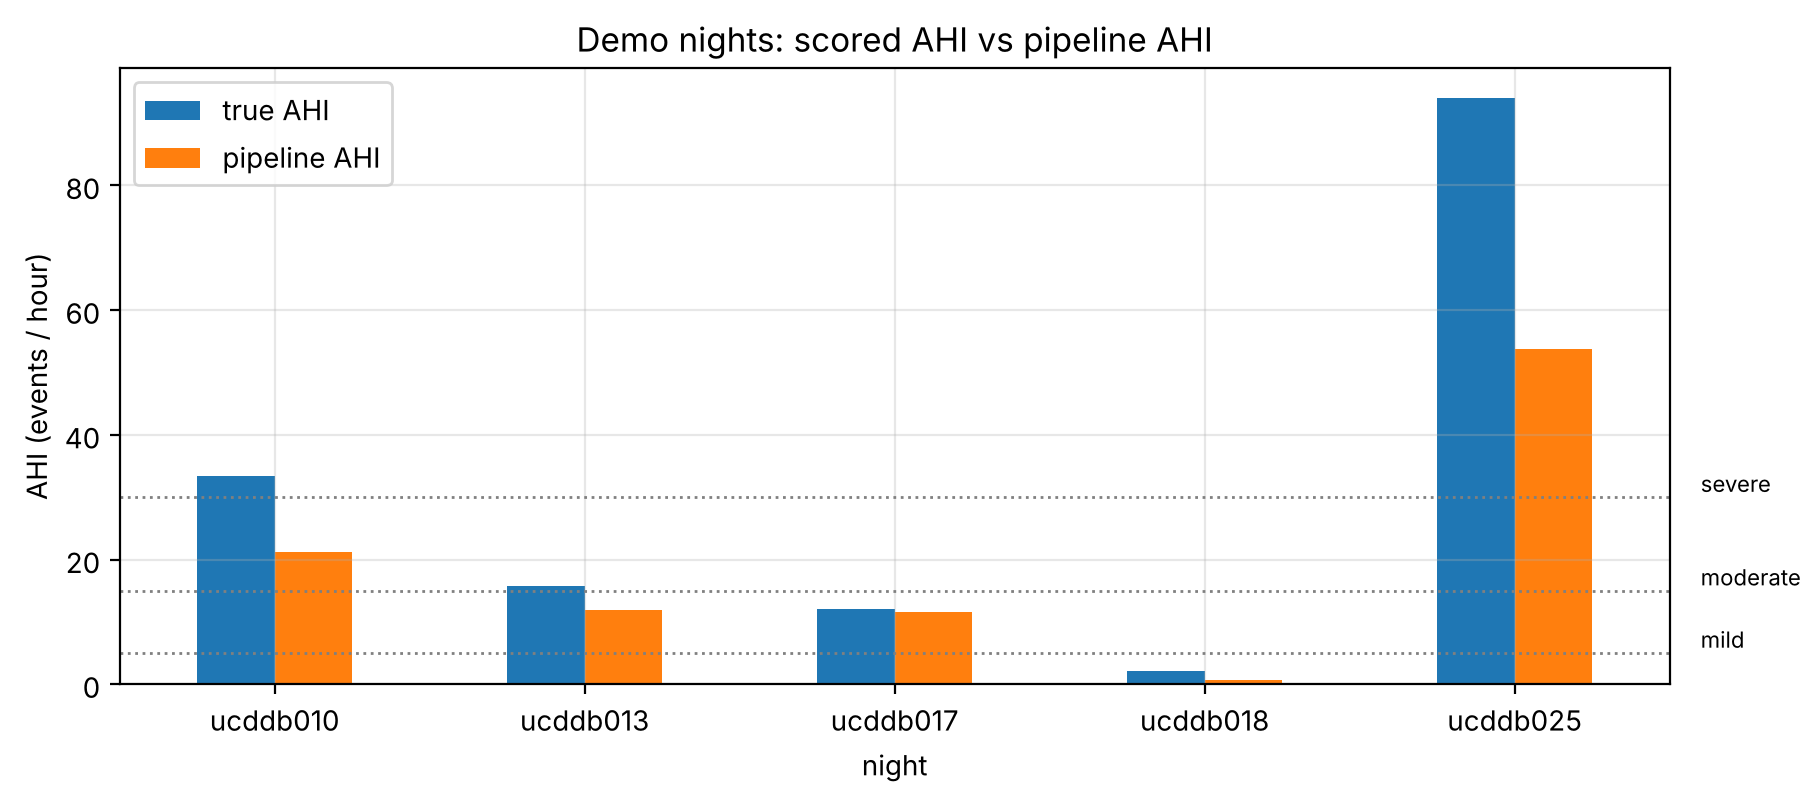

In [25]:
ax = summary[["true AHI", "pipeline AHI"]].plot.bar(figsize=(10, 4), rot=0)
for y, name in [(5, "mild"), (15, "moderate"), (30, "severe")]:
    ax.axhline(y, color="grey", ls=":", lw=1); ax.text(4.6, y, name, va="bottom", fontsize=8)
ax.set_ylabel("AHI (events / hour)"); ax.set_title("Demo nights: scored AHI vs pipeline AHI"); plt.show()

## Going further

- Change `NIGHT` at the top (e.g. `ucddb025`, AHI 94) and run everything again (*Run All*).
- In part 3, look at `feat[["flow_s_below_10", "prev_spo2_drop", "event"]]` around an event:
  the oxygen drop often shows up in `prev_…` of the next minute.
- In part 5b, change `DEADLINE_MARGIN_MIN` (`D.DEADLINE_MARGIN_MIN = 60`) and run the cell again.
- Still missing for the real pipeline: device-simulator, carbon-scheduler, alert-service, doctor-dashboard
  and the LLM summary in ahi-triage.